# NB04: Run Layered and CLI Walkthrough

This notebook shows how a simulation run is driven from files and how the
command-line interfaces are organised. You will learn:

1. How the standalone layered runner (`relic.interfaces.cli.run_layered`) turns
   a JSON/YAML config file and an initial-state file into a `RELICSimulator` run
2. Which settings the runner passes to the simulator, including the
   `state_units` declaration that a tutorial-only state variable needs
3. How the unified CLI (`relic.interfaces.cli.main`) is organised into
   subcommands, and which of them run a simulation (`stochastic sde` and
   `stochastic gillespie`, for bound stochastic processes only)
4. What the run reports: the multi-rate group sizes in the log and the final
   state in the saved output file

**Prerequisites:** NB01-NB03.

**Theory Reference:** `docs/source/coertheory.md`, Corollary 2.5.5 (topological
fingerprint) and Section 3.6, Theorem 3.6.1 (DAG compilation and deterministic
topological order).

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
The run below uses the actual `run_layered` entry point, `RELICSimulator`, and the parameter manager.
It registers no Functors: it shows the file-driven run lifecycle, not a scientific process.
NB05 runs real hydrosphere and pedosphere Functors.


### Layered Architecture and Execution

Within each multi-rate group (fast, medium, slow), `RELICSimulator` orders the
registered Functors by a topological sort of their required and optional (not
lagged) same-group dependencies (`compute_group_execution_orders` in
`relic/core/simulator/scale_ops.py`); lagged dependencies are recorded but add
no ordering edge. Among Functors that are ready at the
same time, the one registered first runs first; a dependency cycle raises, and
there is no unsorted fallback order. For a GraphIR, `compile_graph(...)` orders
the executable nodes with Kahn's algorithm, taking the smallest ready node id
first (`_toposort` in `relic/orchestration/compiler.py`, **Theorem 3.6.1**):
if it returns a plan order $\pi$ for $\mathcal{G} = (V, E)$, the graph is a
DAG and

$$
(u, v) \in E \implies \pi(u) < \pi(v).
$$

The **topological fingerprint** (**Corollary 2.5.5**) summarizes the structure
of $\mathcal{G}$ through its incidence matrix $\mathbf{B}$:

$$
\sigma(\mathcal{G}) = \bigl(n,\; m,\; \mathrm{rank}(\mathbf{B}),\; \kappa,\; \beta_1\bigr)
$$

where $n = |V|$, $m = |E|$, $\kappa = \dim\ker(\mathbf{B}^\top)$ is the number
of connected components (budget partitions) and
$\beta_1 = \dim\ker(\mathbf{B})$ is the number of independent cycles. It
depends only on the graph structure, not on parameter values. For a GraphIR,
`relic.orchestration.topology_algebra.get_topology_signature` returns these
quantities (`n_nodes`, `n_links`, `rank`, `nullity` $= \kappa$,
`betti_number` $= \beta_1$).

The run in this notebook registers no Functors, so all three groups are empty
(the run log reports `fast=0, medium=0, slow=0`).

## Setup and Imports

Import the core RELIC components and the CLI utilities for
configuration-driven simulation.
Importing `relic.interfaces.cli.main` leaves root logging unchanged.
Only its command-line `main()` installs the handler; notebooks may configure
logging explicitly when lifecycle messages are wanted.

In [1]:
from __future__ import annotations

# Windows: new asyncio event loops use the selector loop (the default is the proactor loop).
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import argparse
import json
import os
import sys
from pathlib import Path

DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", os.getcwd()))

def locate_project_root() -> Path:
    candidates = [
        Path.cwd().resolve(),
        *Path.cwd().resolve().parents,
        DEFAULT_PROJECT_ROOT,
    ]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "relic").is_dir() and (candidate / "docs" / "source" / "architecture_overview.md").is_file():
            return candidate
    raise FileNotFoundError("Project root not found. Set RELIC_PROJECT_ROOT if needed.")

def extract_subcommands(parser: argparse.ArgumentParser) -> list[str]:
    commands: list[str] = []
    for action in parser._actions:
        if isinstance(action, argparse._SubParsersAction):
            commands.extend(action.choices.keys())
    return sorted(set(commands))

PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from relic.interfaces.cli.main import create_main_parser
from relic.interfaces.cli.run_layered import run_layered_simulation, setup_parser as setup_layered_parser

OUTPUT_DIR = PROJECT_ROOT / "tutorial" / "primary" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SANDBOX_DIR = OUTPUT_DIR / "run_layered_cli_sandbox"
SANDBOX_DIR.mkdir(parents=True, exist_ok=True)

print("[OK] project_root =", PROJECT_ROOT)
print("[OK] sandbox_dir =", SANDBOX_DIR)


[OK] project_root = <RELIC_ROOT>
[OK] sandbox_dir = tutorial\primary\output\run_layered_cli_sandbox


## Configuration-Driven Simulation

RELIC has typed configuration models: `ConfigLoader.load_config` in
`relic/core/config/loader.py` returns a Pydantic `RELICConfig`. It composes a
configuration directory with Hydra, reads a single file directly, and then
applies dotted overrides and environment overrides. The unified CLI loads this
configuration for its global `--config` option.

The layered runner used in this notebook does not use those models.
`run_layered_simulation()` reads a JSON or YAML mapping, takes its `simulation`
section (or the whole mapping when there is no such section), and passes it
unchanged to `RELICSimulator(config=...)` as the simulator settings. It has no
Functor section. The only way the file can register Functors is the test-only
bootstrap setting `enable_bootstrap_modules`: when it is true and no Functor is
registered, `initialize_state` registers the Functors named by the setting
`bootstrap_functors`, else `bootstrap_functor_name`, else the parameter
`computation.simulator_bootstrap.default_functor_name` (`bucket_soil_moisture`),
in the fast group (`_maybe_register_bootstrap_functors` in
`relic/core/simulator/state_init.py`). This registration is allowed when the
environment variable `RELIC_ALLOW_BOOTSTRAP_MODULES` is on (`1`, `true`, `yes`,
`on`); unless that variable is set to an off value, it is also allowed when
pytest is loaded or the setting `allow_bootstrap_modules` is true. Otherwise
`initialize_state` raises `RuntimeError: enable_bootstrap_modules is test-only`.
The config below sets `enable_bootstrap_modules: False` (also the default), so
the run registers no Functors and only carries the initial state forward in
time.

## Parameter System (Zero-Hardcoding Policy)

RELIC's parameter system enforces a **zero-hardcoding policy**: all
parameter values, units, bounds, and metadata are stored in YAML files
under `relic/parameters/database/`.

**Parameter access in Functors** uses a single canonical method:

```python
value = self.get_parameter_value("param_name", required=True)
```

**Parameter access outside Functors** uses the global manager:

```python
from relic.parameters import get_global_manager
manager = get_global_manager()
value = manager.get("namespace.param_name")
```

Each YAML parameter entry must include:
`value`, `units`, `dtype`, `bounds`, `category`, `description`,
`references`, `tags`, `requires_grad`, `provenance`.
Numeric dtypes declare both bounds endpoints; `-.inf`/`.inf` denote unbounded
sides. `bounds: null` is allowed only for nonnumeric dtypes. Numeric
`value/default/bounds` must be YAML numbers. Write `1.0e+7` and `1.0e-6`:
PyYAML reads `1.0e7` and `1e-6` as text, which ParameterSpec rejects rather
than silently converting.


In [2]:
# References:
# - relic/parameters/manager.py (UnifiedParameterManager.get, get_parameter)
# - relic/parameters/database/ (YAML parameter specs)
# - docs/source/architecture_overview.md, Parameter System (Zero Hardcoding)
#
# Mathematical expression (optional bounds of manager.get):
#   v = min(max(raw_value, lower), upper)   only when bounds=(lower, upper) is passed
# Parameter meanings:
#   raw_value: value stored in the YAML database (converted when units= is passed)
#   lower, upper: the caller's bounds=(lower, upper) argument; a None side is not applied
# Units:
#   v, raw_value, lower and upper share the parameter's units (the requested units= when given)
# Domain/constraints:
#   clamping applies to numeric scalars (int, float, one-element tensor) only;
#   a clamped value emits a UserWarning; without bounds= no clamping happens
# Sign convention:
#   not applicable (no flux or source term)

from relic.parameters import get_global_manager

manager = get_global_manager()
print(f"ParameterManager type: {type(manager).__name__}")

# Show core API methods
api_methods = ["get", "get_parameter"]
for method_name in api_methods:
    has_method = hasattr(manager, method_name)
    print(f"  manager.{method_name}(): {'available' if has_method else 'NOT found'}")

# Demonstrate parameter retrieval pattern
# In a real Functor, use self.get_parameter_value("name", required=True)
# Outside Functors, use manager.get("namespace.key")
print()
print("Parameter access patterns:")
print("  Inside Functor:  self.get_parameter_value('name', required=True)")
print("  Outside Functor: manager.get('namespace.key')")
print("[OK] ParameterManager API demonstration complete")

ParameterManager type: UnifiedParameterManager
  manager.get(): available
  manager.get_parameter(): available

Parameter access patterns:
  Inside Functor:  self.get_parameter_value('name', required=True)
  Outside Functor: manager.get('namespace.key')
[OK] ParameterManager API demonstration complete


In [3]:
main_parser = create_main_parser()
main_cli_commands = extract_subcommands(main_parser)

layered_parser = argparse.ArgumentParser(prog="run_layered")
setup_layered_parser(layered_parser)
layered_cli_help = layered_parser.format_help()
layered_cli_flags = [
    "--config",
    "--initial-state",
    "--output",
    "--format",
    "--start-time",
    "--end-time",
    "--dt",
]

cli_summary = {
    "main_cli_top_level_commands": main_cli_commands,
    "run_layered_is_standalone": "run_layered" not in main_cli_commands,
    "layered_cli_flags": layered_cli_flags,
    "layered_help_contains_output": "--output" in layered_cli_help,
    "layered_help_contains_initial_state": "--initial-state" in layered_cli_help,
}

cli_summary

{'main_cli_top_level_commands': ['compute',
  'data',
  'graph',
  'health',
  'healthcheck',
  'opt',
  'optimization',
  'orchestration',
  'params',
  'stoch',
  'stochastic'],
 'run_layered_is_standalone': True,
 'layered_cli_flags': ['--config',
  '--initial-state',
  '--output',
  '--format',
  '--start-time',
  '--end-time',
  '--dt'],
 'layered_help_contains_output': True,
 'layered_help_contains_initial_state': True}

## CLI Walkthrough

The unified CLI (`python -m relic.interfaces.cli.main`) groups parameter
management (`params`), data I/O (`data`), compute diagnostics (`compute`),
stochastic tools (`stochastic`/`stoch`), optimization components
(`optimization`/`opt`), GraphIR validation and compilation
(`orchestration`/`graph`) and health checks (`healthcheck`/`health`). The cell
above read these names from `create_main_parser()`. No subcommand runs a model
from a simulator configuration file the way the layered runner does; the
layered runner is a separate module,
`python -m relic.interfaces.cli.run_layered --config ... --output ...`, and the
package installs no `relic` console script. Two subcommands do run a
simulation, but only of a bound stochastic process: `stochastic sde`
(`stochastic_air_temperature`) and `stochastic gillespie`
(`stochastic_rainfall`) build the process graph, compile it with
`compile_graph(...)` and execute it with `GraphExecutor`, which drives a
`RELICSimulator` for `--steps` fixed steps of `--dt` seconds
(`execute_bound_stochastic_process` in `relic/stochastic/workflows.py`).

`run_layered_simulation()` accepts only paths inside the API data root: the
`RELIC_API_DATA_ROOT` environment variable, else the project root
(`validate_safe_local_path` in `relic/interfaces/api/schemas.py`). The next
cell writes the config and initial-state files into a sandbox folder and
points `RELIC_API_DATA_ROOT` at it.

Every initial-state variable needs declared units. They come from an SCM
contract (`relic/contracts/variables`), the SSOT variable catalog, the
parameter `validation.numerical.state_variable_bounds`, or the simulator
setting `state_units`. `state_units` may also name a variable declared in one
of the other sources, but only with the same units; different units raise
`ValueError`. `tutorial_scalar` is a tutorial-only variable declared nowhere
else, so the config declares it through `state_units` (`"1"`, dimensionless).
Without that declaration `initialize_state` raises
`ValueError: Initial-state variables without declared units`.

In [4]:
# Simulator settings, passed unchanged to RELICSimulator(config=...).
# state_units declares units of initial-state variables. Units can also come from
# an SCM contract, the SSOT catalog or validation.numerical.state_variable_bounds;
# a variable declared there may be named here only with the same units, otherwise
# initialize_state raises ValueError. tutorial_scalar is declared nowhere else and
# is dimensionless ("1").
# enable_bootstrap_modules False (also the default) keeps the test-only bootstrap
# Functor registration off, so this run registers no Functors.
config_payload = {
    "simulation": {
        "time_step": 1.0,
        "max_time": 2.0,
        "enable_bootstrap_modules": False,
        "conservation_checks": False,
        "strict_dependencies": False,
        "state_units": {"tutorial_scalar": "1"},
    }
}

initial_state_payload = {
    "tutorial_scalar": 1.5
}

config_path = SANDBOX_DIR / "tutorial_run_layered_config.json"
state_path = SANDBOX_DIR / "tutorial_run_layered_state.json"
run_output_path = SANDBOX_DIR / "tutorial_run_layered_output.json"

config_path.write_text(json.dumps(config_payload, indent=2, ensure_ascii=True), encoding="utf-8")
state_path.write_text(json.dumps(initial_state_payload, indent=2, ensure_ascii=True), encoding="utf-8")
os.environ["RELIC_API_DATA_ROOT"] = str(SANDBOX_DIR.resolve())

print("[OK] config_path =", config_path)
print("[OK] state_path =", state_path)
print("[OK] RELIC_API_DATA_ROOT =", os.environ["RELIC_API_DATA_ROOT"])

[OK] config_path = tutorial\primary\output\run_layered_cli_sandbox\tutorial_run_layered_config.json
[OK] state_path = tutorial\primary\output\run_layered_cli_sandbox\tutorial_run_layered_state.json
[OK] RELIC_API_DATA_ROOT = tutorial\primary\output\run_layered_cli_sandbox


In [5]:
# References:
# - relic/interfaces/cli/run_layered.py (run_layered_simulation)
# - relic/core/simulator/execution_loop.py (run_simulation: the time loop of RELICSimulator.run)
# Mathematical expression (time loop, adaptive_dt_enabled False, the default):
#   t = start_time
#   while t < end_time: dt_k = min(dt, end_time - t); step(dt_k); t = t + dt_k
#   (t = t + dt_k is a floating-point sum; with adaptive_dt_enabled True the loop
#   uses the controller's next step _adaptive_next_dt in place of dt)
# Parameter meanings:
# - start_time, end_time: simulation start and end time
# - t: simulation clock; dt_k: length of step k
# - dt: requested time step; the last step is shortened so the run ends at end_time
# - tutorial_scalar: tutorial state variable; with no registered Functor it keeps its initial value
# Units:
# - start_time, end_time, dt: s
# - tutorial_scalar: 1 (dimensionless, declared through state_units)
# Domain/constraints:
# - dt > 0; the loop takes no step when end_time <= start_time
# - rounding in t = t + dt_k can leave t just below end_time and add one final
#   step of near-zero length (dt = 0.1 over [0, 1] takes 11 steps, not 10);
#   dt = 1.0 over [0, 2] here takes exactly 2 steps
# - config, initial-state and output paths must lie inside RELIC_API_DATA_ROOT
# Sign convention:
# - time advances forward; no flux or source term is applied in this run

run_result = run_layered_simulation(
    config_path=str(config_path.resolve()),
    initial_state_path=str(state_path.resolve()),
    output_path=str(run_output_path.resolve()),
    output_format="json",
    start_time=0.0,
    end_time=2.0,
    dt=1.0,
)

saved_payload = json.loads(run_output_path.read_text(encoding="utf-8"))

run_summary = {
    "status": run_result.get("status"),
    "result_type": run_result.get("result_type"),
    "saved_output_exists": run_output_path.exists(),
    "saved_results": saved_payload.get("results", {}),
}

run_summary

{'status': 'ok',
 'result_type': 'dict',
 'saved_output_exists': True,
 'saved_results': {'tutorial_scalar': 1.5,
  'time': 2.0,
  'step': 2,
  'state_var': 0.0}}

In [6]:
summary = {
    "cli": cli_summary,
    "run_layered": run_summary,
    "paths": {
        "config_path": str(config_path.resolve()),
        "state_path": str(state_path.resolve()),
        "run_output_path": str(run_output_path.resolve()),
    },
}

assert "compute" in summary["cli"]["main_cli_top_level_commands"]
assert "params" in summary["cli"]["main_cli_top_level_commands"]
assert "optimization" in summary["cli"]["main_cli_top_level_commands"]
assert "stochastic" in summary["cli"]["main_cli_top_level_commands"]
assert summary["cli"]["run_layered_is_standalone"] is True
assert summary["cli"]["layered_help_contains_output"] is True
assert summary["cli"]["layered_help_contains_initial_state"] is True
assert summary["run_layered"]["status"] == "ok"
assert summary["run_layered"]["result_type"] == "dict"
assert summary["run_layered"]["saved_output_exists"] is True
assert summary["run_layered"]["saved_results"]["tutorial_scalar"] == 1.5
assert summary["run_layered"]["saved_results"]["time"] == 2.0
assert summary["run_layered"]["saved_results"]["step"] == 2

output_path = OUTPUT_DIR / "run_layered_walkthrough_summary.json"
output_path.write_text(json.dumps(summary, indent=2, ensure_ascii=True), encoding="utf-8")

print("[OK] wrote", output_path)
print("[OK] main_cli_commands =", ",".join(summary["cli"]["main_cli_top_level_commands"]))
print("[OK] run_layered_final_time =", summary["run_layered"]["saved_results"]["time"])
print("[OK] run_layered_step =", summary["run_layered"]["saved_results"]["step"])

[OK] wrote tutorial\primary\output\run_layered_walkthrough_summary.json
[OK] main_cli_commands = compute,data,graph,health,healthcheck,opt,optimization,orchestration,params,stoch,stochastic
[OK] run_layered_final_time = 2.0
[OK] run_layered_step = 2


## Visualize Simulation Output

Plot the final values saved by `run_layered_simulation()`. The saved `results`
mapping is the simulator state at `end_time`: `tutorial_scalar` (still 1.5,
because no Functor is registered), the control entries `time` (2.0 s) and
`step` (2 steps), and `state_var` (0.0), a zero control entry that
`RELICSimulator` adds to the state it returns when no variable of that name
exists. The bars mix quantities with different units; they are single end
values, not a trajectory.


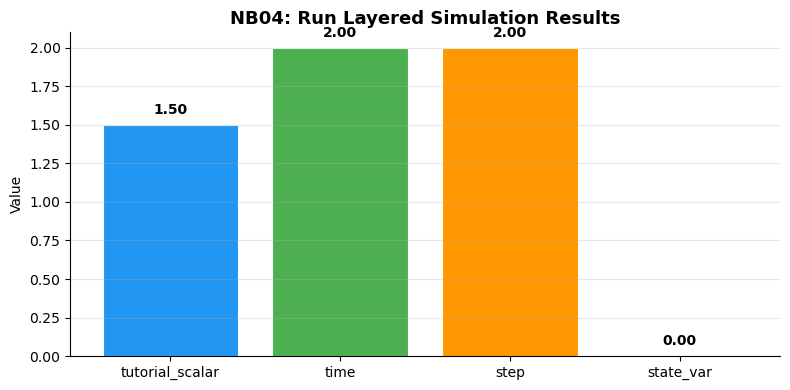

In [7]:
import matplotlib.pyplot as plt

# References:
#   relic/interfaces/cli/run_layered.py (saved "results" = return value of RELICSimulator.run)
#   relic/core/simulator/state_ops.py (get_current_state adds time, step and state_var)
# Mathematical expression:
#   final_state = initial_state   (no Functor is registered, so no update is applied)
# Parameter meanings:
#   tutorial_scalar: tutorial state variable
#   state_var: zero control entry added by get_current_state when the state has no 'state_var'
#   time: simulation clock at the end of the run
#   step: number of accepted steps
# Units:
#   tutorial_scalar: 1 (dimensionless); time: s; step: count; state_var: none (control entry)
# Domain/constraints:
#   single end values; the bars share one axis although their units differ
# Sign convention:
#   not applicable (no flux or source term)

results = saved_payload.get('results', {})
labels = list(results.keys())
values = [float(v) for v in results.values()]

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']
bars = ax.bar(labels, values, color=colors[:len(labels)], edgecolor='white', linewidth=0.8)

# Add value labels on bars
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            f'{val:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title('NB04: Run Layered Simulation Results', fontsize=13, fontweight='bold')
ax.set_ylabel('Value')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## Summary

This notebook showed:
- The standalone layered runner: a JSON config (`simulation` section) and an
  initial-state file drive `RELICSimulator` through `run_layered_simulation()`,
  which saves the final state to a JSON file
- The declared-units rule: a tutorial-only state variable gets its units from
  the simulator setting `state_units`
- The unified CLI subcommands, read from `create_main_parser()`; none runs a
  model from a config file like the layered runner, but `stochastic sde` and
  `stochastic gillespie` run the bound stochastic processes through
  `compile_graph(...)` and `GraphExecutor`
- The run log: all multi-rate groups were empty (no registered Functors), so
  `tutorial_scalar` kept its initial value 1.5 over 2 steps to t = 2.0 s

**Next:** Proceed to **NB05** for real hydrosphere and pedosphere processes.